In [1]:
# Import required libraries

import pandas as pd
import numpy as np

from sklearn.mixture import GaussianMixture

import random
from datetime import datetime, timedelta

# Set random seeds for reproducibility
np.random.seed(42)
random.seed(42)

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
from sklearn.mixture import GaussianMixture
import numpy as np

# Define spending patterns
# Values represent the average log transaction amount.
means = np.array([
    [np.log(300)],    # Low spending
    [np.log(3000)],   # Medium spending
    [np.log(20000)]   # High spending
])

# Define standard deviations for each spending group
covariances = np.array([
    [[0.5]],
    [[0.7]],
    [[0.6]]
])

# Define probability of each spending group
weights = np.array([0.60, 0.30, 0.10])

# Create Gaussian Mixture Model
gmm = GaussianMixture(
    n_components=3,
    covariance_type="full",
    random_state=42
)

# Manually configure the model distributions
gmm.weights_ = weights
gmm.means_ = means
gmm.covariances_ = covariances
gmm.precisions_cholesky_ = np.linalg.cholesky(
    np.linalg.inv(covariances)
)

# Generate 1000 synthetic transaction amounts
log_amounts, spending_groups = gmm.sample(1000)

# Convert log amounts into actual currency amounts
amounts = np.exp(log_amounts.flatten())

# Round amounts to two decimal places
amounts = np.round(amounts, 2)

print("Generated transaction amounts successfully!")
print("Total transactions:", len(amounts))
print("First 10 transaction amounts:")
print(amounts[:10])

Generated transaction amounts successfully!
Total transactions: 1000
First 10 transaction amounts:
[916.4  516.17 215.25 440.29 216.18 215.82 355.98  77.55  88.6  201.58]


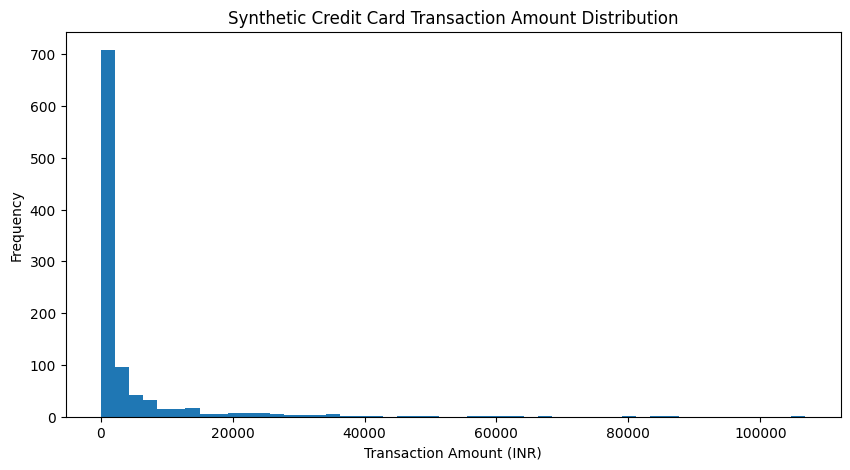

In [3]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.hist(amounts, bins=50)

plt.title("Synthetic Credit Card Transaction Amount Distribution")
plt.xlabel("Transaction Amount (INR)")
plt.ylabel("Frequency")

plt.show()

In [4]:
# Define merchant categories and their probabilities

merchant_data = {
    "Grocery": {
        "merchants": ["Reliance Fresh", "D-Mart", "BigBasket"],
        "probability": 0.30
    },
    "Shopping": {
        "merchants": ["Amazon", "Flipkart", "Myntra"],
        "probability": 0.25
    },
    "Food": {
        "merchants": ["Swiggy", "Zomato", "McDonalds"],
        "probability": 0.20
    },
    "Travel": {
        "merchants": ["Uber", "Ola", "MakeMyTrip"],
        "probability": 0.15
    },
    "Entertainment": {
        "merchants": ["Netflix", "BookMyShow", "Spotify"],
        "probability": 0.10
    }
}

# Extract categories and their probabilities
categories = list(merchant_data.keys())

probabilities = [
    merchant_data[category]["probability"]
    for category in categories
]

# Generate category for each transaction
transaction_categories = np.random.choice(
    categories,
    size=1000,
    p=probabilities
)

# Select a merchant based on the generated category
merchants = [
    random.choice(merchant_data[category]["merchants"])
    for category in transaction_categories
]

print("Merchant generation completed!")
print("First 10 merchants:", merchants[:10])
print("Category distribution:")
print(pd.Series(transaction_categories).value_counts())


Merchant generation completed!
First 10 merchants: ['Myntra', 'Netflix', 'Swiggy', 'McDonalds', 'D-Mart', 'Reliance Fresh', 'Reliance Fresh', 'Uber', 'McDonalds', 'Swiggy']
Category distribution:
Grocery          319
Shopping         240
Food             198
Travel           143
Entertainment    100
Name: count, dtype: int64


In [5]:
from datetime import datetime, timedelta

# Define the transaction date range
start_date = datetime(2026, 1, 1)
end_date = datetime(2026, 10, 31)

# Generate random dates within the date range
date_range_days = (end_date - start_date).days

transaction_dates = [
    start_date + timedelta(
        days=random.randint(0, date_range_days),
        seconds=random.randint(0, 86399)
    )
    for _ in range(1000)
]

print("Transaction dates generated successfully!")
print("First 10 transaction dates:")

for date in transaction_dates[:10]:
    print(date)

Transaction dates generated successfully!
First 10 transaction dates:
2026-10-13 15:09:08
2026-04-26 19:01:34
2026-07-14 16:24:09
2026-08-15 10:49:34
2026-10-29 15:36:47
2026-06-06 20:42:11
2026-01-31 22:11:45
2026-02-20 07:33:55
2026-04-19 09:38:07
2026-02-11 05:43:05


In [6]:
# Define synthetic cities and payment channels

cities = ["Chennai", "Mumbai", "Delhi", "Bangalore", "Hyderabad"]
city_probabilities = [0.30, 0.25, 0.20, 0.15, 0.10]

payment_channels = ["Online", "POS", "Contactless"]
channel_probabilities = [0.45, 0.35, 0.20]

# Generate transaction attributes
transaction_ids = [
    f"TXN{i:06d}" for i in range(1, 1001)
]

card_ids = [
    f"CARD{random.randint(1, 200):04d}"
    for _ in range(1000)
]

transaction_cities = np.random.choice(
    cities, size=1000, p=city_probabilities
)

payment_methods = np.random.choice(
    payment_channels, size=1000, p=channel_probabilities
)

# Generate simulated fraud labels
fraud_labels = []

for amount, channel in zip(amounts, payment_methods):

    # Higher-value transactions have a higher simulated fraud probability
    fraud_probability = 0.02

    if amount > 50000:
        fraud_probability += 0.20

    if channel == "Online":
        fraud_probability += 0.03

    fraud_labels.append(
        np.random.choice(
            [0, 1],
            p=[1 - fraud_probability, fraud_probability]
        )
    )

print("Additional transaction attributes generated!")
print("Total transaction IDs:", len(transaction_ids))
print("Total card IDs:", len(card_ids))
print("Total fraud labels:", len(fraud_labels))

Additional transaction attributes generated!
Total transaction IDs: 1000
Total card IDs: 1000
Total fraud labels: 1000


In [7]:
# Combine generated attributes into one dataset

synthetic_data = pd.DataFrame({

    "transaction_id": transaction_ids,

    "card_id": card_ids,

    "amount": amounts,

    "merchant": merchants,

    "merchant_category": transaction_categories,

    "transaction_date": transaction_dates,

    "city": transaction_cities,

    "payment_channel": payment_methods,

    "is_fraud": fraud_labels
})

# Sort transactions by date
synthetic_data = synthetic_data.sort_values(
    by="transaction_date"
).reset_index(drop=True)

print("Synthetic dataset created successfully!")

print("\nFirst 10 transactions:")
display(synthetic_data.head(10))

print("\nDataset information:")
print(synthetic_data.info())

Synthetic dataset created successfully!

First 10 transactions:


,transaction_id,card_id,amount,merchant,merchant_category,transaction_date,city,payment_channel,is_fraud
0,TXN000467,CARD0152,102.76,Reliance Fresh,Grocery,2026-01-01 22:23:04,Hyderabad,Online,0
1,TXN000058,CARD0103,128.76,D-Mart,Grocery,2026-01-01 23:56:40,Mumbai,Online,0
2,TXN000806,CARD0146,2076.55,McDonalds,Food,2026-01-02 00:49:39,Bangalore,Contactless,0
3,TXN000788,CARD0024,1030.87,Amazon,Shopping,2026-01-02 07:56:00,Delhi,Online,0
4,TXN000220,CARD0079,647.93,Uber,Travel,2026-01-02 10:05:42,Chennai,Online,0
5,TXN000087,CARD0085,182.61,McDonalds,Food,2026-01-02 10:17:52,Delhi,Online,0
6,TXN000452,CARD0079,144.28,Zomato,Food,2026-01-03 02:53:04,Delhi,Contactless,0
7,TXN000965,CARD0082,22086.39,Reliance Fresh,Grocery,2026-01-03 11:13:25,Delhi,Contactless,0
8,TXN000716,CARD0185,717.33,Spotify,Entertainment,2026-01-03 20:02:15,Hyderabad,Online,0
9,TXN000748,CARD0063,7243.85,Myntra,Shopping,2026-01-04 09:29:41,Chennai,Online,0



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   transaction_id     1000 non-null   object        
 1   card_id            1000 non-null   object        
 2   amount             1000 non-null   float64       
 3   merchant           1000 non-null   object        
 4   merchant_category  1000 non-null   object        
 5   transaction_date   1000 non-null   datetime64[ns]
 6   city               1000 non-null   object        
 7   payment_channel    1000 non-null   object        
 8   is_fraud           1000 non-null   int64         
dtypes: datetime64[ns](1), float64(1), int64(1), object(6)
memory usage: 70.4+ KB
None


In [8]:
# Validate the generated dataset

print("Total rows:", len(synthetic_data))

print("Total columns:", len(synthetic_data.columns))

print("Duplicate transactions:",
      synthetic_data["transaction_id"].duplicated().sum())

print("Missing values:")
print(synthetic_data.isnull().sum())

print("\nFraud distribution:")
print(synthetic_data["is_fraud"].value_counts())

print("\nMerchant category distribution:")
print(synthetic_data["merchant_category"].value_counts())

print("\nTransaction amount statistics:")
print(synthetic_data["amount"].describe())

Total rows: 1000
Total columns: 9
Duplicate transactions: 0
Missing values:
transaction_id       0
card_id              0
amount               0
merchant             0
merchant_category    0
transaction_date     0
city                 0
payment_channel      0
is_fraud             0
dtype: int64

Fraud distribution:
is_fraud
0    970
1     30
Name: count, dtype: int64

Merchant category distribution:
merchant_category
Grocery          319
Shopping         240
Food             198
Travel           143
Entertainment    100
Name: count, dtype: int64

Transaction amount statistics:
count      1000.000000
mean       4216.728610
std       10419.507995
min          30.320000
25%         253.072500
50%         533.145000
75%        2918.220000
max      106845.320000
Name: amount, dtype: float64


In [9]:
# Export synthetic transactions to CSV

file_name = "synthetic_credit_card_transactions.csv"

synthetic_data.to_csv(file_name, index=False)

print(f"\nCSV exported successfully: {file_name}")


CSV exported successfully: synthetic_credit_card_transactions.csv


In [10]:
from google.colab import files

files.download("synthetic_credit_card_transactions.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>